# Assignment №3 — Natural Language Processing

**Выполнил:** Maidangali Backhtiyar  
**Дата:** 23 октября 2026 г.

## 1. Введение

Цель работы — реализовать и экспериментально сравнить методы NLP для анализа
тональности, многодокументного суммирования, классификации музыкальных жанров и
идентификации языка. Все таблицы метрик, матрицы ошибок и примеры ошибок ниже
формируются из реальных предсказаний. Тестовые данные не используются при выборе
гиперпараметров.

Датасеты: `cardiffnlp/tweet_eval`, Multi-News, 
`juliensimon/autonlp-data-song-lyrics` и `ymoslem/Tatoeba-Translations`.
Зафиксировано случайное зерно 42.

## 2. Настройка окружения

### 2.1 Импорты библиотек

In [1]:
import json
import os
# BART generation uses a small operation not implemented by every MPS build.
# PyTorch will execute only unsupported MPS operations on CPU.
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")
import random
import re
import sys
import urllib.request
import warnings
from collections import Counter
from importlib.metadata import version
from pathlib import Path

import evaluate
import fasttext
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from datasets import concatenate_datasets, load_dataset
from huggingface_hub import hf_hub_download
from IPython.display import Markdown, display
from nltk.corpus import stopwords, wordnet
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import sent_tokenize, word_tokenize
from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix, f1_score,
    precision_score, recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import normalize
from transformers import pipeline

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 180)
sns.set_theme(style="whitegrid", palette="colorblind")

/Users/bahus/miniconda3/lib/python3.11/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/Users/bahus/miniconda3/lib/python3.11/site-packages/transformers/utils/generic.py:482: UserWarning: torch.utils._pytree._register_pytree_node is deprecated. Please use torch.utils._pytree.register_pytree_node instead.
  _torch_pytree._register_pytree_node(
/Users/bahus/miniconda3/lib/python3.11/site-packages/torchvision/io/image.py:13: UserWarning: Failed to load image Python extension: 'dlopen(/Users/bahus/miniconda3/lib/python3.11/site-packages/torchvision/image.so, 0x0006): Symbol not found: __ZN3c1017RegisterOperatorsD1Ev
  Referenced from: <CFED5F8E-EC3F-36FD-AAA3-2C6C7F8D3DD9> /Users/bahus/miniconda3/lib/python3.11/site-packages/torchvision/image.so
  Expected in:     <30F09B34-7715-34CE-8167-500A7159D315> /Users/bahus/miniconda3/lib/python3.11/site-packages/torch/lib/libtorch_cpu.dylib'If you don't plan on using image functionality from `torchvision.io`, you can ignore this warning. Otherwise, there might be something wrong with your environment. Did you have `libjpeg` or `libp

/Users/bahus/miniconda3/lib/python3.11/site-packages/bitsandbytes/cextension.py:34: UserWarning: The installed version of bitsandbytes was compiled without GPU support. 8-bit optimizers, 8-bit multiplication, and GPU quantization are unavailable.
  warn("The installed version of bitsandbytes was compiled without GPU support. "


'NoneType' object has no attribute 'cadam32bit_grad_fp32'


/Users/bahus/miniconda3/lib/python3.11/site-packages/transformers/utils/generic.py:339: UserWarning: torch.utils._pytree._register_pytree_node is deprecated. Please use torch.utils._pytree.register_pytree_node instead.
  _torch_pytree._register_pytree_node(
/Users/bahus/miniconda3/lib/python3.11/site-packages/transformers/utils/generic.py:339: UserWarning: torch.utils._pytree._register_pytree_node is deprecated. Please use torch.utils._pytree.register_pytree_node instead.
  _torch_pytree._register_pytree_node(


### 2.2 Случайное зерно и ресурсы NLTK

In [2]:
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

for resource in ["punkt", "stopwords", "wordnet", "omw-1.4", "vader_lexicon"]:
    nltk.download(resource, quiet=True)

EN_STOPWORDS = set(stopwords.words("english"))
LEMMATIZER = WordNetLemmatizer()
LABEL_NAMES = ["Negative", "Neutral", "Positive"]

### 2.3 Конфигурация и версии

In [3]:
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT / "NLP_Assignment_3").exists():
    PROJECT_ROOT = PROJECT_ROOT / "NLP_Assignment_3"
DATA_DIR = PROJECT_ROOT / "data"

runtime_device = 0 if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else -1)
device_name = "CUDA" if runtime_device == 0 else ("Apple MPS" if runtime_device == "mps" else "CPU")
packages = ["numpy", "pandas", "scikit-learn", "nltk", "datasets", "transformers", "torch", "evaluate"]
environment = pd.DataFrame({"Package": packages, "Version": [version(name) for name in packages]})
print(f"Python: {sys.version.split()[0]} | Device: {device_name} | RANDOM_STATE={RANDOM_STATE}")
display(environment)

Python: 3.11.5 | Device: Apple MPS | RANDOM_STATE=42


,Package,Version
0,numpy,1.23.5
1,pandas,2.1.3
2,scikit-learn,1.5.2
3,nltk,3.8.1
4,datasets,2.16.1
5,transformers,4.44.2
6,torch,2.2.0.dev20231129
7,evaluate,0.4.6


## 3. Задание 1 — Анализ тональности

### 3.1 Цель

Сравниваются VADER, TF-IDF + Logistic Regression и предварительно обученная
Transformer-модель. Исследовательский вопрос: даёт ли Transformer существенный
прирост Macro F1 относительно словарного и традиционного подходов?

### 3.2 Датасет

TweetEval Sentiment содержит метки `negative`, `neutral`, `positive`. Исходные
разбиения объединяются, дубликаты удаляются, затем создаётся новая
стратифицированная схема 70/15/15. Для практичного запуска берётся
воспроизводимая сбалансированная выборка 1500 текстов каждого класса (4500 всего),
что превышает минимум задания.

In [4]:
tweet_data = load_dataset("cardiffnlp/tweet_eval", "sentiment")
print("Splits:", tweet_data)
print("Columns:", tweet_data["train"].column_names)
print("Features:", tweet_data["train"].features)
display(pd.DataFrame(tweet_data["train"][:3]))

tweet_all = concatenate_datasets([tweet_data[split] for split in tweet_data.keys()]).to_pandas()
tweet_all["text_key"] = tweet_all["text"].str.strip().str.casefold()
duplicates_t1 = int(tweet_all["text_key"].duplicated().sum())
tweet_all = tweet_all.drop_duplicates("text_key").drop(columns="text_key")
raw_distribution_t1 = tweet_all["label"].value_counts().sort_index()
print(f"После объединения: {len(tweet_all):,}; удалено дубликатов: {duplicates_t1:,}")
display(raw_distribution_t1.rename(index=dict(enumerate(LABEL_NAMES))).to_frame("count"))

sentiment_df = (
    tweet_all.groupby("label", group_keys=False)
    .sample(n=1500, random_state=RANDOM_STATE)
    .sample(frac=1, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)
train_t1, temp_t1 = train_test_split(
    sentiment_df, test_size=0.30, random_state=RANDOM_STATE, stratify=sentiment_df["label"]
)
valid_t1, test_t1 = train_test_split(
    temp_t1, test_size=0.50, random_state=RANDOM_STATE, stratify=temp_t1["label"]
)
assert not (set(train_t1.text) & set(valid_t1.text) | set(train_t1.text) & set(test_t1.text) | set(valid_t1.text) & set(test_t1.text))
print({"total": len(sentiment_df), "train": len(train_t1), "validation": len(valid_t1), "test": len(test_t1)})

ax = sentiment_df["label"].map(dict(enumerate(LABEL_NAMES))).value_counts().reindex(LABEL_NAMES).plot.bar()
ax.set(title="Распределение классов TweetEval", xlabel="Тональность", ylabel="Количество текстов")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

Splits: DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 45615
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 12284
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})
Columns: ['text', 'label']
Features: {'text': Value(dtype='string', id=None), 'label': ClassLabel(names=['negative', 'neutral', 'positive'], id=None)}


,text,label
0,"""QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #HappyBirthdayRemusLupin""",2
1,"""Ben Smith / Smith (concussion) remains out of the lineup Thursday, Curtis #NHL #SJ""",1
2,Sorry bout the stream last night I crashed out but will be on tonight for sure. Then back to Minecraft in pc tomorrow night.,1


После объединения: 59,866; удалено дубликатов: 33


,count
label,
Negative,11374
Neutral,27459
Positive,21033


{'total': 4500, 'train': 3150, 'validation': 675, 'test': 675}


<Figure size 640x480 with 1 Axes>

### 3.3 Предварительная обработка

Для TF-IDF применяются нижний регистр, токенизация, удаление ссылок, упоминаний,
пунктуации и стоп-слов, затем лемматизация. VADER получает почти исходный текст,
поскольку регистр, восклицания и отрицания входят в его эвристику. Transformer
получает исходный текст через собственный токенизатор. Чрезмерная очистка может
уничтожить `not`, эмодзи и усилители эмоциональности.

In [5]:
def normalize_english(text):
    text = re.sub(r"https?://\S+|www\.\S+|@\w+", " ", str(text).lower())
    tokens = [token for token in word_tokenize(text) if token.isalpha()]
    tokens = [LEMMATIZER.lemmatize(token) for token in tokens if token not in EN_STOPWORDS or token == "not"]
    return " ".join(tokens)

preprocessing_demo_t1 = train_t1.head(5)[["text"]].copy()
preprocessing_demo_t1["processed"] = preprocessing_demo_t1["text"].map(normalize_english)
display(preprocessing_demo_t1)

,text,processed
1477,Good morning Bomb Squad family! I hope you all have a lovely Saturday!,good morning bomb squad family hope lovely saturday
2009,I plan on playing in the @user Pro Series this Friday and Saturday. Anyone else? Free shot at $250 on both XB1 and PS4!,plan playing pro series friday saturday anyone else free shot
2925,"@user @user @user begging for book sales & playing a victim isnt cool, PC crap is over",begging book sale playing victim isnt cool pc crap
1335,"@user @user If FOX keeps building the show guy up. You may be right. Start building up Dr. Ben Carson and Carly Fiorina,""",fox keep building show guy may right start building ben carson carly fiorina
1791,How I feel after post #Thanksgiving headed to #BlackFriday looking for deals and doing my #cardio on... #Doyoueven?…,feel post thanksgiving headed blackfriday looking deal cardio doyoueven


### 3.4 VADER

In [6]:
vader = SentimentIntensityAnalyzer()

def vader_predict(texts, threshold=0.05):
    scores = np.array([vader.polarity_scores(text)["compound"] for text in texts])
    predictions = np.where(scores > threshold, 2, np.where(scores < -threshold, 0, 1))
    return predictions, scores

vader_validation = []
for threshold in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]:
    predictions, _ = vader_predict(valid_t1["text"], threshold)
    vader_validation.append({"threshold": threshold, "macro_f1": f1_score(valid_t1.label, predictions, average="macro")})
vader_validation = pd.DataFrame(vader_validation)
best_vader_threshold = float(vader_validation.loc[vader_validation.macro_f1.idxmax(), "threshold"])
display(vader_validation)
print("Выбранный порог:", best_vader_threshold)
vader_pred_t1, vader_scores_t1 = vader_predict(test_t1["text"], best_vader_threshold)

,threshold,macro_f1
0,0.05,0.577693
1,0.10,0.578862
2,0.15,0.567344
3,0.20,0.558750
4,0.25,0.552384
5,0.30,0.552816


Выбранный порог: 0.1


### 3.5 TF-IDF + Logistic Regression

In [7]:
def make_sentiment_lr(c_value):
    return Pipeline([
        ("tfidf", TfidfVectorizer(preprocessor=normalize_english, lowercase=False,
                                  ngram_range=(1, 2), min_df=2, max_features=40000, sublinear_tf=True)),
        ("model", LogisticRegression(C=c_value, max_iter=1000, class_weight="balanced",
                                     random_state=RANDOM_STATE)),
    ])

lr_validation = []
for c_value in [0.1, 1.0, 10.0]:
    candidate = make_sentiment_lr(c_value)
    candidate.fit(train_t1.text, train_t1.label)
    predictions = candidate.predict(valid_t1.text)
    lr_validation.append({"C": c_value, "macro_f1": f1_score(valid_t1.label, predictions, average="macro")})
lr_validation = pd.DataFrame(lr_validation)
best_c_t1 = float(lr_validation.loc[lr_validation.macro_f1.idxmax(), "C"])
display(lr_validation)
print("Лучшее C:", best_c_t1)

lr_sentiment = make_sentiment_lr(best_c_t1)
lr_sentiment.fit(pd.concat([train_t1.text, valid_t1.text]), pd.concat([train_t1.label, valid_t1.label]))
lr_pred_t1 = lr_sentiment.predict(test_t1.text)

,C,macro_f1
0,0.1,0.548650
1,1.0,0.550230
2,10.0,0.537566


Лучшее C: 1.0


### 3.6 Transformer

Используется `cardiffnlp/twitter-roberta-base-sentiment-latest` без дообучения.
Инференс выполняется пакетами; входы обрезаются до 512 токенов.

In [8]:
SENTIMENT_MODEL = "cardiffnlp/twitter-roberta-base-sentiment-latest"
transformer_sentiment = pipeline(
    "text-classification", model=SENTIMENT_MODEL, tokenizer=SENTIMENT_MODEL,
    device=runtime_device
)
transformer_output_t1 = transformer_sentiment(
    test_t1.text.tolist(), batch_size=32, truncation=True, max_length=512
)

def sentiment_label_to_id(label):
    label = label.lower()
    if "negative" in label or label.endswith("0"):
        return 0
    if "neutral" in label or label.endswith("1"):
        return 1
    if "positive" in label or label.endswith("2"):
        return 2
    raise ValueError(f"Неизвестная метка Transformer: {label}")

transformer_pred_t1 = np.array([sentiment_label_to_id(item["label"]) for item in transformer_output_t1])
display(pd.DataFrame(transformer_output_t1).head())

Some weights of the model checkpoint at cardiffnlp/twitter-roberta-base-sentiment-latest were not used when initializing RobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


,label,score
0,neutral,0.761524
1,neutral,0.865040
2,negative,0.896434
3,negative,0.898834
4,neutral,0.918516


### 3.7 Оценка и сравнение

,Model,Accuracy,Precision Macro,Recall Macro,F1 Macro
2,Transformer,0.757,0.774,0.757,0.761
1,TF-IDF + Logistic Regression,0.581,0.586,0.581,0.582
0,VADER,0.561,0.570,0.561,0.562


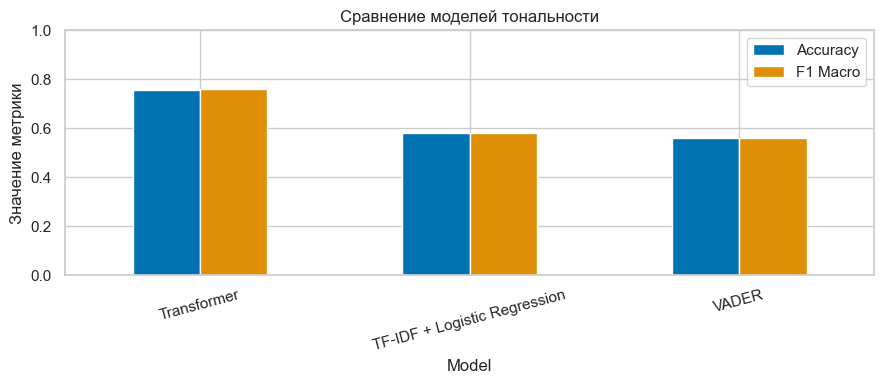

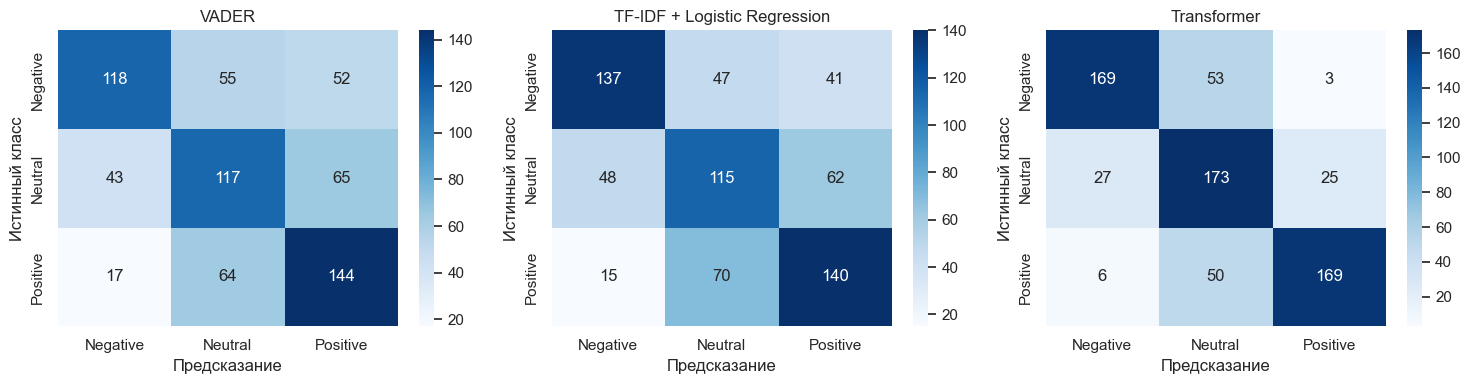

In [9]:
def classification_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision Macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall Macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1 Macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

predictions_t1 = {
    "VADER": vader_pred_t1,
    "TF-IDF + Logistic Regression": lr_pred_t1,
    "Transformer": transformer_pred_t1,
}
results_t1 = pd.DataFrame([
    {"Model": model, **classification_metrics(test_t1.label, prediction)}
    for model, prediction in predictions_t1.items()
]).sort_values("F1 Macro", ascending=False)
display(results_t1.style.format({column: "{:.3f}" for column in results_t1.columns[1:]}))

results_t1.set_index("Model")[["Accuracy", "F1 Macro"]].plot.bar(figsize=(9, 4), ylim=(0, 1))
plt.title("Сравнение моделей тональности"); plt.ylabel("Значение метрики"); plt.xticks(rotation=15); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, (model, prediction) in zip(axes, predictions_t1.items()):
    matrix = confusion_matrix(test_t1.label, prediction, labels=[0, 1, 2])
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", ax=axis,
                xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES)
    axis.set(title=model, xlabel="Предсказание", ylabel="Истинный класс")
plt.tight_layout(); plt.show()

### 3.8 Анализ ошибок и вывод

In [10]:
errors_t1 = test_t1[["text", "label"]].copy()
errors_t1["VADER"] = vader_pred_t1
errors_t1["Logistic Regression"] = lr_pred_t1
errors_t1["Transformer"] = transformer_pred_t1
errors_t1 = errors_t1[errors_t1["Transformer"] != errors_t1["label"]].head(5).copy()
for column in ["label", "VADER", "Logistic Regression", "Transformer"]:
    errors_t1[column] = errors_t1[column].map(dict(enumerate(LABEL_NAMES)))
display(errors_t1)

best_t1 = results_t1.iloc[0]
transformer_f1_t1 = float(results_t1.loc[results_t1.Model == "Transformer", "F1 Macro"].iloc[0])
lr_f1_t1 = float(results_t1.loc[results_t1.Model == "TF-IDF + Logistic Regression", "F1 Macro"].iloc[0])
display(Markdown(
    f"**Вывод.** Лучший подход — **{best_t1['Model']}** (Macro F1 = {best_t1['F1 Macro']:.3f}). "
    f"Разница Transformer и TF-IDF + Logistic Regression равна {transformer_f1_t1-lr_f1_t1:+.3f}. "
    "Ошибки в показанных примерах связаны с контекстом, неоднозначностью, сарказмом и неявной эмоциональной оценкой; "
    "поэтому вывод об улучшении делается по измеренной разнице, а не по ожиданию от архитектуры."
))

,text,label,VADER,Logistic Regression,Transformer
3920,"""Nightlife in Milan, Italy: Aperitif and evening at Fiat Open Lounge - english page - For the ones tomorrow sunda...""",Positive,Neutral,Neutral,Neutral
3131,@user idk about Thalia but I gotta work Saturday :/,Neutral,Negative,Positive,Negative
4373,@user like how are ppl supposed to pay rent? Should i ask the pope on the 26th when he comes?,Negative,Positive,Negative,Neutral
2204,My dad tried to tell me that Hillary winning the popular vote doesn't matter because America is a republic and not a democracy.,Neutral,Positive,Neutral,Negative
1013,Face like miss America... Body like a stripper... Fuck me like a pornstar... N handle business like the 1st lady... Yea i need that...$$$,Positive,Positive,Negative,Neutral


**Вывод.** Лучший подход — **Transformer** (Macro F1 = 0.761). Разница Transformer и TF-IDF + Logistic Regression равна +0.179. Ошибки в показанных примерах связаны с контекстом, неоднозначностью, сарказмом и неявной эмоциональной оценкой; поэтому вывод об улучшении делается по измеренной разнице, а не по ожиданию от архитектуры.

## 4. Задание 2 — Автоматическое суммирование

### 4.1 Цель и выбор данных

Сравниваются экстрактивное ранжирование предложений по TF-IDF и иерархическое
абстрактивное суммирование BART. Репозиторий `tau/multi_news` на момент проверки
возвращал из устаревшей Google Drive ссылки данные, не декодируемые как UTF-8.
Поэтому прозрачно использовано зеркало исходного Multi-News
`mehdielg/multi_news`. Зафиксирован пример `train[32766]`: ровно пять связанных
статей, каждая длиннее 250 слов, эталон — 147 слов. Тексты сохранены в `data/` и
не выбираются заново при каждом запуске.

In [11]:
summary_dir = DATA_DIR / "summarization"
with open(summary_dir / "metadata.json", encoding="utf-8") as file:
    summary_metadata = json.load(file)
selected_articles = [
    (summary_dir / f"article_{index}.txt").read_text(encoding="utf-8").strip()
    for index in range(1, 6)
]
reference_summary = (summary_dir / "reference_summary.txt").read_text(encoding="utf-8").strip()
document_info = pd.DataFrame({
    "Document": [f"Article {index}" for index in range(1, 6)],
    "Word Count": [len(article.split()) for article in selected_articles],
    "Topic": ["Назначение шерифа Дэвида Кларка в DHS"] * 5,
    "Source": ["Multi-News (mehdielg mirror), train[32766]"] * 5,
})
display(pd.Series(summary_metadata, name="value"))
display(document_info)
print(f"Reference summary ({len(reference_summary.split())} words):\n{reference_summary}")

requested_repository                                                                   tau/multi_news
actual_repository                                                                 mehdielg/multi_news
reason                        tau/multi_news returned a non-UTF-8 Google Drive response on 2026-10-23
split                                                                                           train
stream_position_zero_based                                                                      32766
article_word_counts                                                         [333, 965, 540, 349, 826]
summary_word_count                                                                                147
Name: value, dtype: object

,Document,Word Count,Topic,Source
0,Article 1,333,Назначение шерифа Дэвида Кларка в DHS,"Multi-News (mehdielg mirror), train[32766]"
1,Article 2,965,Назначение шерифа Дэвида Кларка в DHS,"Multi-News (mehdielg mirror), train[32766]"
2,Article 3,540,Назначение шерифа Дэвида Кларка в DHS,"Multi-News (mehdielg mirror), train[32766]"
3,Article 4,349,Назначение шерифа Дэвида Кларка в DHS,"Multi-News (mehdielg mirror), train[32766]"
4,Article 5,826,Назначение шерифа Дэвида Кларка в DHS,"Multi-News (mehdielg mirror), train[32766]"


Reference summary (147 words):
Controversial Milwaukee County Sheriff David A. Clarke Jr. says he's accepted a position in the Department of Homeland Security, the Milwaukee Journal-Sentinel reports. Clarke said on a radio talk show Wednesdsay that he'd be leaving his position as sheriff next month to work as an assistant secretary in DHS' Office of Partnership and Engagement, Fox 6 reports. He'll act as a liaison between DHS and state and local law enforcement and governments. The AP notes that DHS has so far declined to confirm his appointment. Clarke, who has been sheriff since 2002, was recently the subject of mass protests over a number of issues, including the death of a Milwaukee County Jail inmate who was allegedly denied water for a week. Per the Raw Story, there have been calls for Clarke to resign since four people, including a baby, died in the jail since he took office.


### 4.2 Предварительная обработка

In [12]:
def clean_document(text):
    return re.sub(r"\s+", " ", text.replace("NEWLINE_CHAR", " ")).strip()

article_sentences = [sent_tokenize(clean_document(article)) for article in selected_articles]
print("Количество предложений:", [len(sentences) for sentences in article_sentences])
print("Пример первого предложения:", article_sentences[0][0])

Количество предложений: [11, 56, 13, 16, 39]
Пример первого предложения: Getty Image Former Arizona Sheriff Joe Arpaio’s unfortunate legacy is still being dismantled after his failed re-election bid last November, but Milwaukee Sheriff David Clarke has been all too willing to assume the unofficial Most Controversial Sheriff in America title.


### 4.3 Экстрактивное суммирование

Предложение оценивается косинусной близостью его TF-IDF-вектора к центроиду
документа. Сначала выбираются три предложения из каждой статьи. Затем 15
кандидатов повторно ранжируются относительно общего центроида; почти дублирующие
предложения с косинусной близостью выше 0.75 исключаются. Финальные шесть
предложений возвращаются в исходный порядок документов.

In [13]:
def centroid_sentence_scores(sentences):
    vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=1)
    matrix = vectorizer.fit_transform(sentences)
    centroid = normalize(np.asarray(matrix.mean(axis=0)))
    scores = np.asarray(matrix @ centroid.T).ravel()
    return scores, matrix

candidates = []
per_article_extracts = []
for document_index, sentences in enumerate(article_sentences):
    scores, _ = centroid_sentence_scores(sentences)
    chosen_indices = sorted(np.argsort(scores)[-3:])
    chosen = []
    for sentence_index in chosen_indices:
        row = {"document": document_index + 1, "sentence_index": sentence_index,
               "sentence": sentences[sentence_index], "local_score": scores[sentence_index]}
        candidates.append(row); chosen.append(row)
    per_article_extracts.append(chosen)

per_article_table = pd.DataFrame(candidates)
display(per_article_table)

candidate_texts = [row["sentence"] for row in candidates]
global_scores, candidate_matrix = centroid_sentence_scores(candidate_texts)
selected_candidate_indices = []
for index in np.argsort(global_scores)[::-1]:
    if not selected_candidate_indices:
        selected_candidate_indices.append(index)
    else:
        similarities = (candidate_matrix[index] @ candidate_matrix[selected_candidate_indices].T).toarray().ravel()
        if similarities.max(initial=0) < 0.75:
            selected_candidate_indices.append(index)
    if len(selected_candidate_indices) == 6:
        break
selected_rows = [candidates[index] for index in selected_candidate_indices]
selected_rows.sort(key=lambda row: (row["document"], row["sentence_index"]))
extractive_summary = " ".join(row["sentence"] for row in selected_rows)
print(f"Extractive summary ({len(extractive_summary.split())} words, 6 sentences):\n{extractive_summary}")

,document,sentence_index,sentence,local_score
0,1,5,"The march is broadly known as the Wisconsin “Day without Latinxs, Immigrants and Refugees,” and CNN spoke to one of the protest’s organizers: “Sheriff Clarke, right off the bat...",0.352100
1,1,7,"With this protest, Milwaukee is poised to become the “national epicenter” to combat 287(g) because, as Neumann-Ortiz notes, Clarke gained national notoriety last summer for his...",0.349292
2,1,9,Madison.com says that Monday’s protests are mainly geared toward preventing Clarke from putting 287(g) into action but will also serve as a general protest against Trump’s depo...,0.373445
3,2,2,"Milwaukee County Sheriff David A. Clarke Jr. (Photo: J. Scott Applewhite, Associated Press) Milwaukee County Sheriff David A. Clarke Jr. said Wednesday he would leave office ne...",0.326302
4,2,12,"— Homeland Security (@DHSgov) May 17, 2017 RELATED: White House considers Milwaukee County Sheriff David Clarke for post in Homeland Security RELATED: Clarke passed over for Tr...",0.320033
5,2,21,"In the new job, one of Clarke's responsibilities would be to ""take complaints of shortcomings in the Department of Homeland Security,"" the sheriff said.",0.289760
6,3,0,"Milwaukee County Sheriff David Clarke David Clarke appears on Fox Business News on Sept. 21, 2016.",0.359262
7,3,8,"However, he is highly controversial in Milwaukee County, where county medical examiner Brian Petersen alleges that Clarke threatened him in an effort to suppress a coroner’s of...",0.363716
8,3,9,Four people — including a newborn baby — have died in the Milwaukee County Jail since Clarke became sheriff.,0.361635
9,4,1,"Clarke says he's taken a job as an assistant secretary in... (Associated Press) FILE - In this July 18, 2016 file photo, Milwaukee County, Wis. Sheriff David Clarke speaks at t...",0.554229


Extractive summary (224 words, 6 sentences):
Milwaukee County Sheriff David A. Clarke Jr. (Photo: J. Scott Applewhite, Associated Press) Milwaukee County Sheriff David A. Clarke Jr. said Wednesday he would leave office next month to accept a federal appointment as an assistant secretary in the U.S. Department of Homeland Security. — Homeland Security (@DHSgov) May 17, 2017 RELATED: White House considers Milwaukee County Sheriff David Clarke for post in Homeland Security RELATED: Clarke passed over for Trump cabinet post OPINION: Clarke's departure will be good for department and Milwaukee County Also, the federal staffer being replaced by Clarke — Philip A. McNamara, assistant secretary for intergovernmental affairs — took to Twitter to complain about his successor. Milwaukee County Sheriff David Clarke David Clarke appears on Fox Business News on Sept. 21, 2016. Clarke says he's taken a job as an assistant secretary in... (Associated Press) FILE - In this July 18, 2016 file photo, Mil

### 4.4 Абстрактивное суммирование

Модель `facebook/bart-large-cnn` используется без дообучения. Каждый документ
делится токенизатором на фрагменты до 900 токенов; каждый фрагмент суммируется,
затем промежуточные резюме иерархически объединяются. Параметры: 4 луча,
`do_sample=False`; для финального шага целевой диапазон 110–180 токенов с
автоматической повторной генерацией, если результат не попал в 100–150 слов.

In [14]:
SUMMARIZATION_MODEL = "facebook/bart-large-cnn"
summarizer = pipeline("summarization", model=SUMMARIZATION_MODEL,
                      tokenizer=SUMMARIZATION_MODEL, device=runtime_device)
summarizer_tokenizer = summarizer.tokenizer

def token_chunks(text, chunk_size=900):
    token_ids = summarizer_tokenizer.encode(text, add_special_tokens=False)
    return [summarizer_tokenizer.decode(token_ids[start:start + chunk_size], skip_special_tokens=True)
            for start in range(0, len(token_ids), chunk_size)]

chunk_summaries = []
for document_index, article in enumerate(selected_articles, start=1):
    chunks = token_chunks(article)
    outputs = summarizer(chunks, max_length=130, min_length=35, num_beams=4,
                         do_sample=False, batch_size=2)
    for output in outputs:
        chunk_summaries.append(output["summary_text"])
    print(f"Article {document_index}: {len(chunks)} chunk(s)")

hierarchy_text = " ".join(chunk_summaries)
while len(summarizer_tokenizer.encode(hierarchy_text, add_special_tokens=False)) > 900:
    hierarchy_outputs = summarizer(token_chunks(hierarchy_text), max_length=130, min_length=40,
                                   num_beams=4, do_sample=False, batch_size=2)
    hierarchy_text = " ".join(item["summary_text"] for item in hierarchy_outputs)

final_min, final_max = 110, 180
for attempt in range(3):
    abstractive_summary = summarizer(
        hierarchy_text, max_length=final_max, min_length=final_min,
        num_beams=4, do_sample=False
    )[0]["summary_text"]
    word_count = len(abstractive_summary.split())
    if 100 <= word_count <= 150:
        break
    if word_count < 100:
        final_min, final_max = min(final_min + 15, 145), min(final_max + 15, 200)
    else:
        final_min, final_max = max(90, final_min - 10), max(140, final_max - 20)
print(f"Abstractive summary ({len(abstractive_summary.split())} words):\n{abstractive_summary}")

Article 1: 1 chunk(s)


Article 2: 2 chunk(s)


Article 3: 1 chunk(s)


Article 4: 1 chunk(s)


Article 5: 2 chunk(s)


Abstractive summary (108 words):
Milwaukee County Sheriff David A. Clarke Jr. says he will leave office next month. Clarke will work as an assistant secretary in the U.S. Department of Homeland Security. Clarke campaigned around the country for then-presidential candidate Donald Trump last year. He has vocalized his desire to have Milwaukee law enforcement aid ICE agents in accordance with the 287(g) program. An inquest has shown that an inmate in Clarke’s jail died of dehydration in 2016 after being deprived of water. The position will be in the Office of Public Partnership and Engagement. Clarke is a frequent Fox News guest. Last year, he earned more than $105,000 in speaking fees.


### 4.5 ROUGE-оценка

,Method,ROUGE-1,ROUGE-2,ROUGE-L
0,Extractive,0.365,0.117,0.201
1,Abstractive,0.462,0.176,0.242


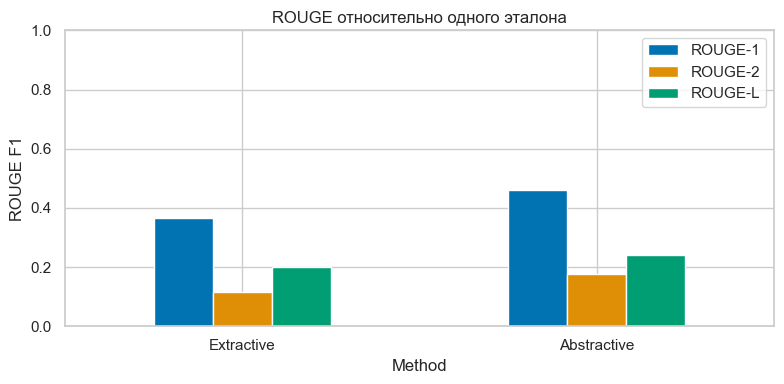

In [15]:
rouge = evaluate.load("rouge")
rouge_rows = []
for method, generated in {"Extractive": extractive_summary, "Abstractive": abstractive_summary}.items():
    scores = rouge.compute(predictions=[generated], references=[reference_summary], use_stemmer=True)
    rouge_rows.append({"Method": method, "ROUGE-1": scores["rouge1"],
                       "ROUGE-2": scores["rouge2"], "ROUGE-L": scores["rougeL"]})
rouge_results = pd.DataFrame(rouge_rows)
display(rouge_results.style.format({"ROUGE-1": "{:.3f}", "ROUGE-2": "{:.3f}", "ROUGE-L": "{:.3f}"}))
rouge_results.set_index("Method").plot.bar(figsize=(8, 4), ylim=(0, 1))
plt.title("ROUGE относительно одного эталона"); plt.ylabel("ROUGE F1"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

### 4.6 Качественный анализ и вывод

In [16]:
source_text = " ".join(selected_articles)
abstractive_sentences = sent_tokenize(abstractive_summary)
support_vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2)).fit(
    article_sentences[0] + article_sentences[1] + article_sentences[2] + article_sentences[3] + article_sentences[4] + abstractive_sentences
)
source_sentence_list = sum(article_sentences, [])
source_matrix = support_vectorizer.transform(source_sentence_list)
generated_matrix = support_vectorizer.transform(abstractive_sentences)
max_support = (generated_matrix @ source_matrix.T).toarray().max(axis=1)
least_supported_sentence = abstractive_sentences[int(np.argmin(max_support))]

reference_sentences = sent_tokenize(reference_summary)
omission_vectorizer = TfidfVectorizer(stop_words="english").fit(reference_sentences + [abstractive_summary])
reference_matrix = omission_vectorizer.transform(reference_sentences)
generated_document_vector = omission_vectorizer.transform([abstractive_summary])
reference_coverage = (reference_matrix @ generated_document_vector.T).toarray().ravel()
omission_candidate = reference_sentences[int(np.argmin(reference_coverage))]

display(pd.DataFrame({
    "Критерий": ["Охват", "Связность", "Избыточность", "Фактическая согласованность", "Грамматика"],
    "Экстрактивное": ["Шесть исходных предложений", "Переходы могут быть резкими", "Возможны повторы",
                        "Формулировки сохранены", "Исходная грамматика"],
    "Абстрактивное": ["Сжимает все фрагменты иерархически", "Обычно более связное", "Сильнее устраняет повторы",
                        "Требует проверки по источникам", "Генерирует цельный текст"],
}))
print("Фактический кандидат на добавление/изменение (минимальная лексическая опора в источниках):")
print(least_supported_sentence, "| support=", round(float(max_support.min()), 3))
print("Фактический кандидат на пропуск (эталонное предложение с минимальным покрытием):")
print(omission_candidate)

best_rouge_method = rouge_results.set_index("Method")["ROUGE-L"].idxmax()
display(Markdown(
    f"**Вывод.** По ROUGE-L лучший результат дал **{best_rouge_method}**. Экстрактивный метод "
    "лучше сохраняет проверяемые формулировки, но хуже связывает разные статьи; BART формирует более плавный текст, "
    "однако перефразирование требует ручной проверки. Выведенные выше предложения — реальные кандидаты из результата, "
    "а не придуманные примеры; низкое лексическое сходство является сигналом, но не доказательством галлюцинации."
))

,Критерий,Экстрактивное,Абстрактивное
0,Охват,Шесть исходных предложений,Сжимает все фрагменты иерархически
1,Связность,Переходы могут быть резкими,Обычно более связное
2,Избыточность,Возможны повторы,Сильнее устраняет повторы
3,Фактическая согласованность,Формулировки сохранены,Требует проверки по источникам
4,Грамматика,Исходная грамматика,Генерирует цельный текст


Фактический кандидат на добавление/изменение (минимальная лексическая опора в источниках):
Clarke will work as an assistant secretary in the U.S. Department of Homeland Security. | support= 0.412
Фактический кандидат на пропуск (эталонное предложение с минимальным покрытием):
The AP notes that DHS has so far declined to confirm his appointment.


**Вывод.** По ROUGE-L лучший результат дал **Abstractive**. Экстрактивный метод лучше сохраняет проверяемые формулировки, но хуже связывает разные статьи; BART формирует более плавный текст, однако перефразирование требует ручной проверки. Выведенные выше предложения — реальные кандидаты из результата, а не придуманные примеры; низкое лексическое сходство является сигналом, но не доказательством галлюцинации.

## 5. Задание 3 — Классификация музыкальных жанров

### 5.1 Цель и датасет

Исследуются Pop, Rock, Hip Hop и Heavy Metal. Репозиторий
`juliensimon/autonlp-data-song-lyrics` заявляет английский язык и шесть жанров.
Его готовые Arrow-файлы имеют несовместимые схемы (`indices` против
`text/target`), поэтому используются собственные raw CSV того же репозитория —
это не замена датасета. После удаления дубликатов берётся по 800 песен каждого
жанра.

Splits: {'train': '/Users/bahus/.cache/huggingface/hub/datasets--juliensimon--autonlp-data-song-lyrics/snapshots/9aa20cbc93690af893e62a2aae8bf4edccdb9e31/raw/train2.csv', 'validation': '/Users/bahus/.cache/huggingface/hub/datasets--juliensimon--autonlp-data-song-lyrics/snapshots/9aa20cbc93690af893e62a2aae8bf4edccdb9e31/raw/val2.csv'}


Columns: ['Lyric', 'Genre0', 'source_split']


,Lyric,Genre0,source_split
0,[Intro: Method Man w/ sample] + (Sunny valentine). We got butter (8X). (The gun'll go the gun'll go.... The gun'll go...). [Raekwon]. Aiyo one thing for sure keep you of all. K...,Hip Hop,train
1,[Sean Paul:]. Aye. It's Sean Paul 'long side. The mandem called Jay Sean. Fi di gal dem. Tellin' 'em again what we tell 'em. [Jay Sean:]. Pass me a drink to the left yeah. Said...,Pop,train
2,Beauty finds refuge in herself. Lovers wrapped inside each others lies. Beauty is such a terrible thing. She is suffering yet more than death. She is suffering. She sucks you d...,Indie,train


,available_unique_lyrics
genre,
Pop,12322
Rock,21040
Hip Hop,9783
Heavy Metal,3032


Удалено дубликатов: 290


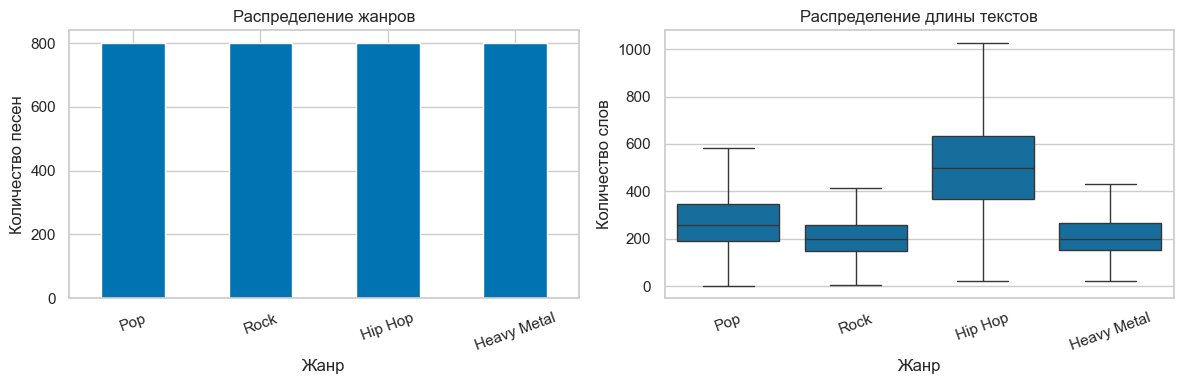

,mean,50%,max
genre,,,
Heavy Metal,219.5100,201.0,2186.0
Hip Hop,496.4800,497.5,1211.0
Pop,275.9825,256.0,803.0
Rock,211.7600,199.5,755.0


In [17]:
SONG_REPOSITORY = "juliensimon/autonlp-data-song-lyrics"
song_paths = {
    split: hf_hub_download(repo_id=SONG_REPOSITORY, filename=filename, repo_type="dataset")
    for split, filename in {"train": "raw/train2.csv", "validation": "raw/val2.csv"}.items()
}
print("Splits:", song_paths)
song_raw = pd.concat([pd.read_csv(path).assign(source_split=split) for split, path in song_paths.items()], ignore_index=True)
print("Columns:", song_raw.columns.tolist()); display(song_raw.head(3))
song_raw = song_raw.rename(columns={"Lyric": "text", "Genre0": "genre"}).dropna(subset=["text", "genre"])
song_raw["text_key"] = song_raw.text.str.strip().str.casefold()
duplicate_songs = int(song_raw.text_key.duplicated().sum())
song_raw = song_raw.drop_duplicates("text_key").drop(columns="text_key")
selected_genres = ["Pop", "Rock", "Hip Hop", "Heavy Metal"]
genre_counts_full = song_raw[song_raw.genre.isin(selected_genres)].genre.value_counts().reindex(selected_genres)
display(genre_counts_full.to_frame("available_unique_lyrics"))
print("Удалено дубликатов:", duplicate_songs)

songs = (song_raw[song_raw.genre.isin(selected_genres)]
         .groupby("genre", group_keys=False).sample(n=800, random_state=RANDOM_STATE)
         .sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True))
songs["word_count"] = songs.text.str.split().str.len()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
songs.genre.value_counts().reindex(selected_genres).plot.bar(ax=axes[0], title="Распределение жанров")
axes[0].set(xlabel="Жанр", ylabel="Количество песен"); axes[0].tick_params(axis="x", rotation=20)
sns.boxplot(data=songs, x="genre", y="word_count", order=selected_genres, ax=axes[1], showfliers=False)
axes[1].set(title="Распределение длины текстов", xlabel="Жанр", ylabel="Количество слов")
axes[1].tick_params(axis="x", rotation=20); plt.tight_layout(); plt.show()
display(songs.groupby("genre").word_count.describe()[["mean", "50%", "max"]])

### 5.2 Предварительная обработка

In [18]:
songs["processed"] = songs.text.map(normalize_english)
display(songs[["genre", "text", "processed"]].head(4))
print("Очистка уменьшает влияние пунктуации и служебных слов, а лемматизация объединяет формы слова; "
      "одновременно могут исчезнуть жанрово значимые стилистические маркеры и разговорные формы.")

,genre,text,processed
0,Pop,This is for them 20 something's. Time really moves fast you were just 16. This is for the 30 something's. That didn't turn out exactly how your mum and dad wanted you to be. Th...,something time really move fast something turn exactly mum dad wanted something well raise glass laugh like motherfucker something hell half way baby take head mum dad tried hi...
1,Rock,Screaming. So you think you can do better. I'm not good enough for you. I'm not scene enough for you. I'm not anything. I don't scream enough for you. I don't sing enough for y...,screaming think better not good enough not scene enough not anything scream enough sing enough not anything way go top bleed enough see enough not anything not damn thing achie...
2,Pop,(1 2 1 2 3 4). I need a man not a boy (4x). Uh uh livin' in the city with brown some so pretty. I I got everyone with me. I'm runnin' this really oh really. I I don't need your...,need man not boy uh uh livin city brown pretty got everyone runnin really oh really need dollar given chance holla tell keep time money homie not payin bill time money give som...
3,Hip Hop,Bababababa. There is no one like me. Th-th-there is no one like me (chiddy bang) like me. Ma-ma-manners take a second look and you'll see. (we pretty much amazing). There is no...,bababababa one like one like chiddy bang like take second look see pretty much amazing one like mind manner people raising glass flow crazy celebrating madness never thought wo...


Очистка уменьшает влияние пунктуации и служебных слов, а лемматизация объединяет формы слова; одновременно могут исчезнуть жанрово значимые стилистические маркеры и разговорные формы.


### 5.3 Частотный анализ

,genre,word,absolute,relative_per_1000
0,Pop,know,1814,17.184051
1,Pop,love,1660,15.725207
2,Pop,like,1387,13.139073
3,Pop,na,1290,12.220191
4,Pop,got,1220,11.557080
5,Pop,oh,1201,11.377092
6,Pop,get,996,9.435124
7,Pop,go,956,9.056203
8,Pop,baby,881,8.345727
9,Pop,let,874,8.279416


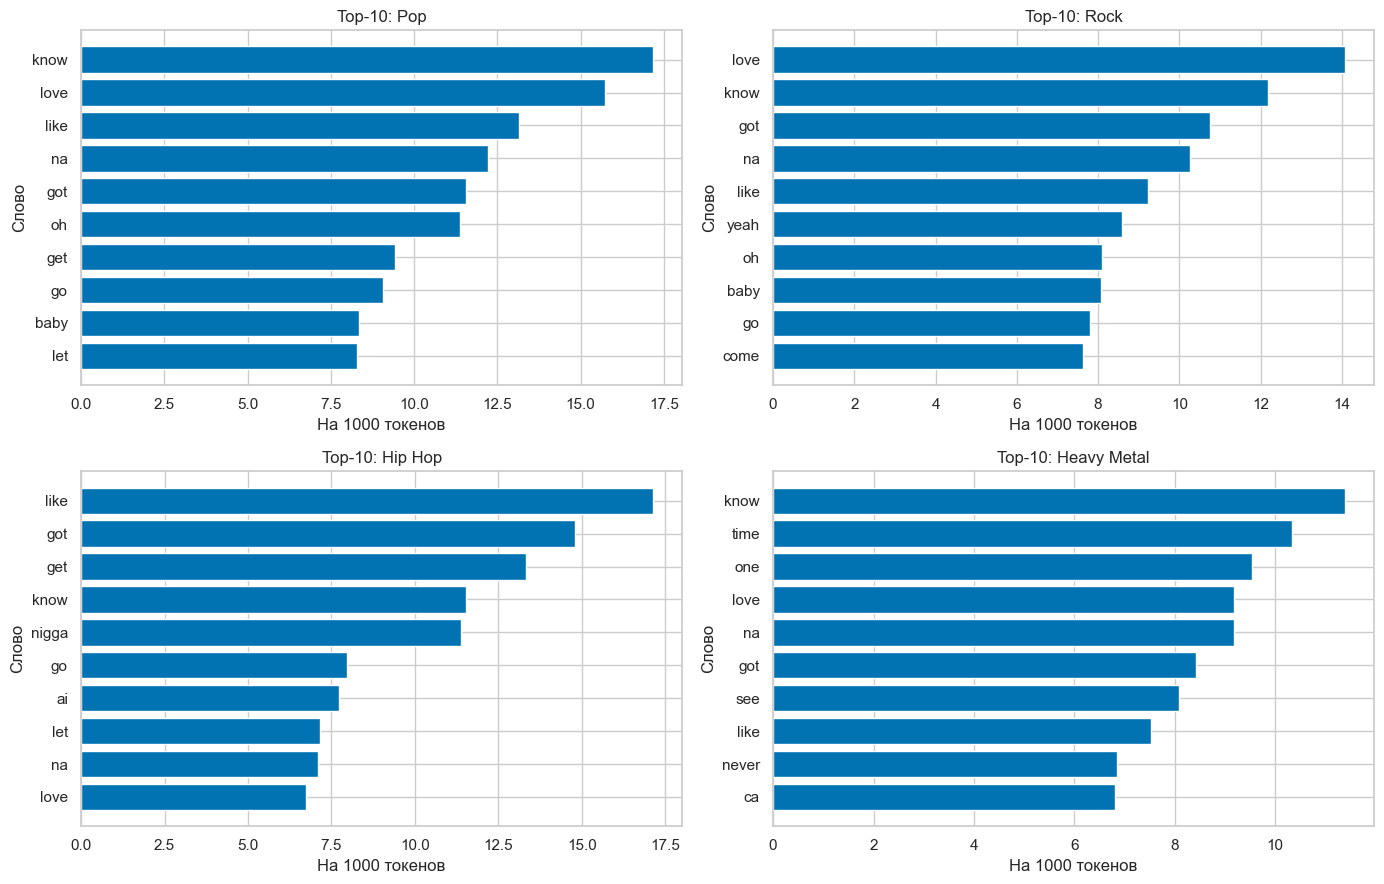

In [19]:
genre_counters = {
    genre: Counter(" ".join(songs.loc[songs.genre == genre, "processed"]).split())
    for genre in selected_genres
}
top_words_rows = []
for genre, counter in genre_counters.items():
    total = sum(counter.values())
    for word, count in counter.most_common(10):
        top_words_rows.append({"genre": genre, "word": word, "absolute": count, "relative_per_1000": count / total * 1000})
top_words = pd.DataFrame(top_words_rows)
display(top_words)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for axis, genre in zip(axes.ravel(), selected_genres):
    subset = top_words[top_words.genre == genre].sort_values("relative_per_1000")
    axis.barh(subset.word, subset.relative_per_1000)
    axis.set(title=f"Top-10: {genre}", xlabel="На 1000 токенов", ylabel="Слово")
plt.tight_layout(); plt.show()

### 5.4 Лексические категории

,genre,category,absolute,relative_per_1000
0,Pop,Time,1374,13.015924
1,Pop,Emotions,2190,20.745905
2,Pop,Body Parts,1659,15.715734
3,Rock,Time,1138,13.678378
4,Rock,Emotions,1638,19.688210
5,Rock,Body Parts,1376,16.539058
6,Hip Hop,Time,1453,7.002511
7,Hip Hop,Emotions,1905,9.180856
8,Hip Hop,Body Parts,1909,9.200133
9,Heavy Metal,Time,1217,14.157418


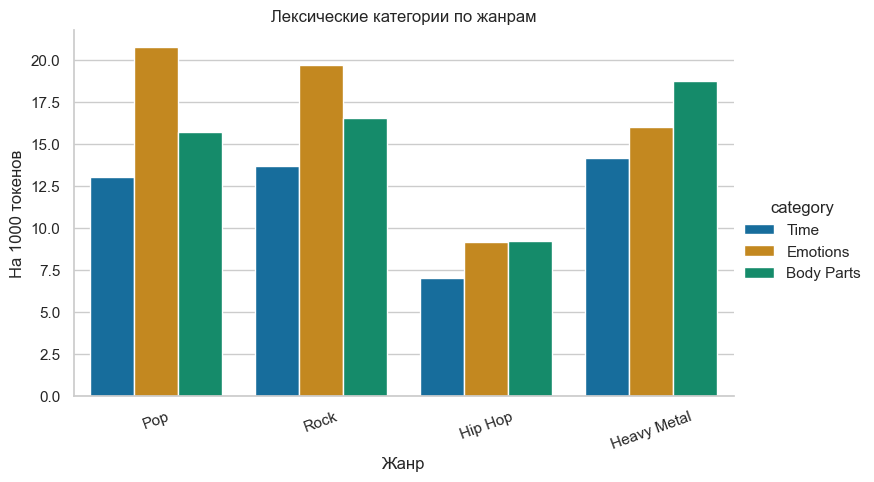

In [20]:
lexical_categories = {
    "Time": {"morning", "evening", "night", "day", "today", "tomorrow", "tonight", "yesterday"},
    "Emotions": {"love", "hate", "happy", "sad", "fear", "anger", "joy", "pain", "lonely"},
    "Body Parts": {"heart", "eye", "hand", "head", "face", "body", "blood", "skin", "mouth"},
}
category_rows = []
for genre, counter in genre_counters.items():
    total = sum(counter.values())
    for category, words in lexical_categories.items():
        count = sum(counter[word] for word in words)
        category_rows.append({"genre": genre, "category": category, "absolute": count,
                              "relative_per_1000": count / total * 1000})
category_frequencies = pd.DataFrame(category_rows)
display(category_frequencies)
sns.catplot(data=category_frequencies, x="genre", y="relative_per_1000", hue="category",
            kind="bar", height=4.5, aspect=1.7)
plt.title("Лексические категории по жанрам"); plt.xlabel("Жанр"); plt.ylabel("На 1000 токенов"); plt.xticks(rotation=20); plt.show()

### 5.5 Редкие и характерные слова

In [21]:
rare_rows = []
for genre, counter in genre_counters.items():
    rare = [(word, count) for word, count in counter.items() if count <= 3]
    rare_rows.append({"genre": genre, "rare_types": len(rare),
                      "examples": ", ".join(word for word, _ in sorted(rare, key=lambda item: (-item[1], item[0]))[:12])})
rare_words = pd.DataFrame(rare_rows)
display(rare_words)

genre_tfidf = TfidfVectorizer(min_df=3, max_df=0.90, max_features=20000, sublinear_tf=True)
genre_matrix = genre_tfidf.fit_transform(songs.processed)
vocabulary = np.array(genre_tfidf.get_feature_names_out())
characteristic_rows = []
for genre in selected_genres:
    mean_scores = np.asarray(genre_matrix[songs.genre.to_numpy() == genre].mean(axis=0)).ravel()
    top_indices = mean_scores.argsort()[-15:][::-1]
    characteristic_rows.append({"genre": genre, "high_tfidf_words": ", ".join(vocabulary[top_indices])})
characteristic_words = pd.DataFrame(characteristic_rows)
display(characteristic_words)
print("Единица TF-IDF-документа — одна песня. Редкое слово может быть опечаткой или именем и почти не повторяться; "
      "характерное слово должно быть заметно внутри жанра и относительно менее типично для остальных документов.")

,genre,rare_types,examples
0,Pop,4622,"aa, abandon, abusin, acrobatic, actually, addicting, adjust, adult, affecting, aisle, album, amber"
1,Rock,4777,"aaah, abandon, ace, ache, achieve, adam, addict, address, affection, aggression, agony, ahh"
2,Hip Hop,10713,"abc, abednago, ability, ablaze, abort, abortion, abouts, absolut, accountant, accustomed, acre, actor"
3,Heavy Metal,4667,"accept, adam, addiction, advantage, agree, airship, alight, allow, amaranth, amends, amount, anarchy"


,genre,high_tfidf_words
0,Pop,"love, know, oh, like, na, got, go, not, baby, time, want, heart, let, ca, one"
1,Rock,"love, know, time, oh, go, like, got, na, baby, never, come, not, one, way, let"
2,Hip Hop,"nigga, like, got, get, ai, shit, know, bitch, na, go, girl, fuck, let, ya, back"
3,Heavy Metal,"time, know, one, see, love, life, never, away, na, ca, feel, got, night, take, come"


Единица TF-IDF-документа — одна песня. Редкое слово может быть опечаткой или именем и почти не повторяться; характерное слово должно быть заметно внутри жанра и относительно менее типично для остальных документов.


### 5.6 Классификация и оценка

{'train': 2560, 'test': 640}
Информация об исполнителе отсутствует, поэтому artist-group split невозможен; это потенциальное ограничение утечки.


,Model,Accuracy,Macro F1
1,Logistic Regression,0.572,0.564
0,Multinomial Naive Bayes,0.541,0.506


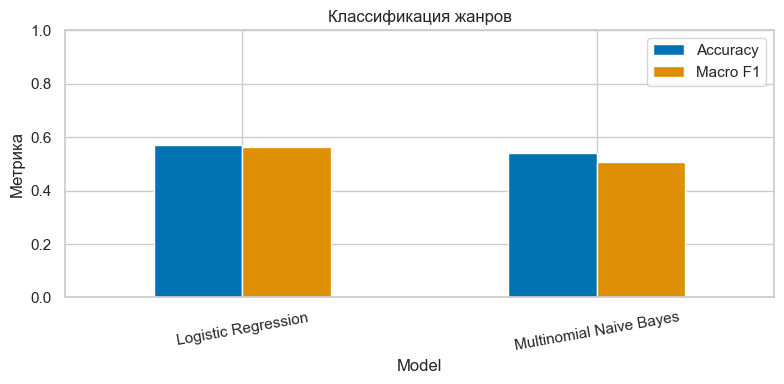

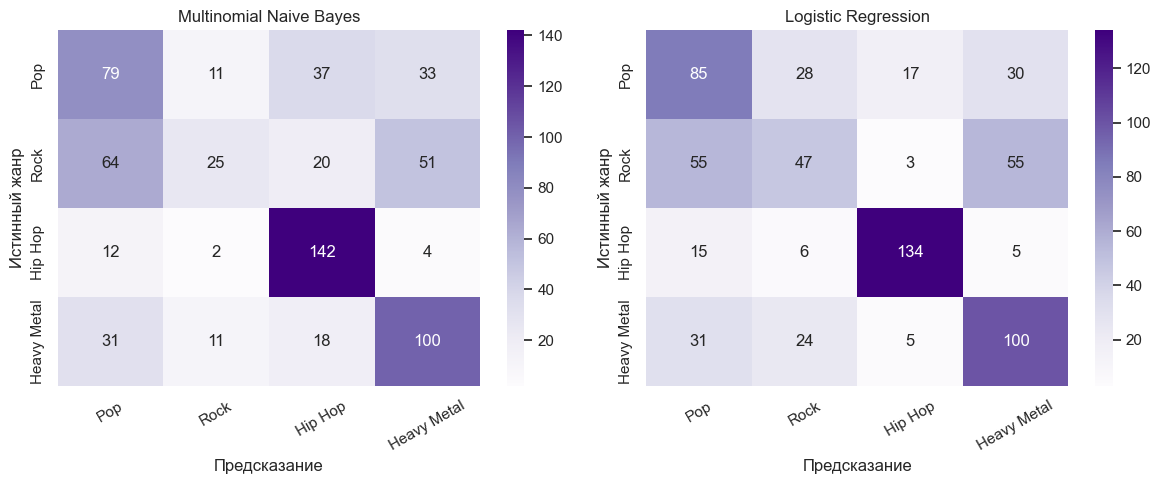

In [22]:
train_t3, test_t3 = train_test_split(
    songs, test_size=0.20, random_state=RANDOM_STATE, stratify=songs.genre
)
print({"train": len(train_t3), "test": len(test_t3)})
print("Информация об исполнителе отсутствует, поэтому artist-group split невозможен; это потенциальное ограничение утечки.")

genre_models = {
    "Multinomial Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000, sublinear_tf=True)),
        ("model", MultinomialNB(alpha=0.5)),
    ]),
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=50000, sublinear_tf=True)),
        ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
}
genre_predictions = {}
genre_result_rows = []
for name, model in genre_models.items():
    model.fit(train_t3.processed, train_t3.genre)
    genre_predictions[name] = model.predict(test_t3.processed)
    genre_result_rows.append({"Model": name,
                              "Accuracy": accuracy_score(test_t3.genre, genre_predictions[name]),
                              "Macro F1": f1_score(test_t3.genre, genre_predictions[name], average="macro")})
genre_results = pd.DataFrame(genre_result_rows).sort_values("Macro F1", ascending=False)
display(genre_results.style.format({"Accuracy": "{:.3f}", "Macro F1": "{:.3f}"}))
genre_results.set_index("Model").plot.bar(figsize=(8, 4), ylim=(0, 1))
plt.title("Классификация жанров"); plt.ylabel("Метрика"); plt.xticks(rotation=10); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for axis, (name, prediction) in zip(axes, genre_predictions.items()):
    matrix = confusion_matrix(test_t3.genre, prediction, labels=selected_genres)
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Purples", ax=axis,
                xticklabels=selected_genres, yticklabels=selected_genres)
    axis.set(title=name, xlabel="Предсказание", ylabel="Истинный жанр")
    axis.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

### 5.7 Анализ ошибок и вывод

In [23]:
best_genre_name = genre_results.iloc[0].Model
best_genre_pred = genre_predictions[best_genre_name]
genre_errors = test_t3[["text", "genre"]].copy()
genre_errors["prediction"] = best_genre_pred
genre_errors = genre_errors[genre_errors.genre != genre_errors.prediction].head(5)
genre_errors["text"] = genre_errors.text.str.slice(0, 350) + "..."
display(genre_errors)

genre_cm = confusion_matrix(test_t3.genre, best_genre_pred, labels=selected_genres)
np.fill_diagonal(genre_cm, 0)
confused_pair_index = np.unravel_index(np.argmax(genre_cm), genre_cm.shape)
confused_pair = f"{selected_genres[confused_pair_index[0]]} → {selected_genres[confused_pair_index[1]]}"
display(Markdown(
    f"**Вывод.** Лучший классификатор — **{best_genre_name}** с Macro F1 = "
    f"{genre_results.iloc[0]['Macro F1']:.3f}. Наиболее частое направленное смешение: **{confused_pair}**. "
    "Лексика действительно содержит жанровый сигнал, но текст не описывает ритм, инструменты, тембр и вокальную технику; "
    "поэтому жанр нельзя полностью восстановить только по словам."
))

,text,genre,prediction
647,They say the hand is quicker than the eye. And two wrongs don't make a right. I feel lightning when you walk by. You got the power to take me higher yeh. Hear me when I say. Ri...,Rock,Heavy Metal
1746,[Verse 1: Snoop Dogg & Gwen Stefani]. Let's forget where we are and what's goin' on. Let's forget who we are and who we know. Why does it gotta be complicated does it have to b...,Hip Hop,Rock
1268,Place my missing picture on my beer I'm running away. from home. Sam I'm just a man a rusted bucket of flesh and. bone. Someday I'll seek forgiveness for the sweet smell of. he...,Heavy Metal,Rock
1674,Carpet stained with my red wine. I've been staring at the fire. I keep looking at the time. I'm waiting on you. I can hear the howling wind. Yes the sound is getting higher. As...,Rock,Heavy Metal
2012,Yayo yayo Mula-la Yayo. Louis Xii and it's all on me honey you just bought a shot. Kamikaze if you think that you gon' knock me off the top. Shit your wife in the backseat of m...,Pop,Hip Hop


**Вывод.** Лучший классификатор — **Logistic Regression** с Macro F1 = 0.564. Наиболее частое направленное смешение: **Rock → Pop**. Лексика действительно содержит жанровый сигнал, но текст не описывает ритм, инструменты, тембр и вокальную технику; поэтому жанр нельзя полностью восстановить только по словам.

## 6. Задание 4 — Идентификация языка

### 6.1 Цель и датасет

Tatoeba хранит пары переводов и использует трёхбуквенные коды (`kaz`, `rus`,
`eng`, `spa`, `por`, `fra`, `deu`), а не ожидаемые двухбуквенные. Из обеих сторон
пар извлечено по 700 уникальных предложений для семи языков, затем коды явно
преобразованы в `kk`, `ru`, `en`, `es`, `pt`, `fr`, `de`. Точная ревизия и
отсутствие дубликатов записаны в metadata; локальный CSV создан программой
`prepare_data.py` непосредственно из Parquet-файлов Hugging Face.

Splits: train (source repository); columns after extraction: ['text', 'language']


repository                               ymoslem/Tatoeba-Translations
revision                     c313a0934b5e2f50f78230fdedfe63ea36e1a05f
source_codes                      [kaz, rus, eng, spa, por, fra, deu]
target_codes                             [kk, ru, en, es, pt, fr, de]
per_language                                                      700
rows                                                             4900
duplicates_after_casefold                                           0
Name: value, dtype: object

,text,language
0,Үй салқын.,kk
1,Сіздің үйіңіз үлкен.,kk
2,Шешем ашулы.,kk
3,Мен колледж студентімін.,kk
4,Aспаз қайда?,kk
5,Мына әңгіменің авторы кім?,kk
6,Ол темекі тартпайды.,kk


,count
language,
de,700
en,700
es,700
fr,700
kk,700
pt,700
ru,700


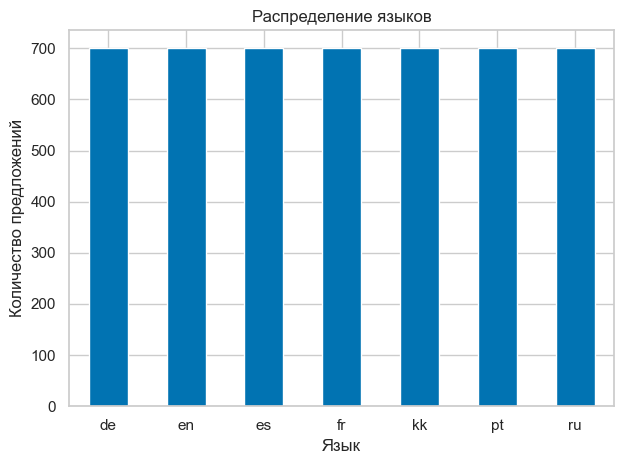

{'train': 3920, 'test': 980}


In [24]:
language_dir = DATA_DIR / "language_id"
language_df = pd.read_csv(language_dir / "tatoeba_7_languages.csv")
language_labels = ["kk", "ru", "en", "es", "pt", "fr", "de"]
with open(language_dir / "metadata.json", encoding="utf-8") as file:
    language_metadata = json.load(file)
print("Splits: train (source repository); columns after extraction:", language_df.columns.tolist())
display(pd.Series(language_metadata, name="value")); display(language_df.head(7))
language_counts = language_df.language.value_counts().sort_index()
display(language_counts.to_frame("count"))
assert language_counts.min() >= 500 and language_df.text.str.casefold().duplicated().sum() == 0
language_counts.plot.bar(title="Распределение языков")
plt.xlabel("Язык"); plt.ylabel("Количество предложений"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

train_t4, test_t4 = train_test_split(
    language_df, test_size=0.20, random_state=RANDOM_STATE, stratify=language_df.language
)
print({"train": len(train_t4), "test": len(test_t4)})

### 6.2 Предварительная обработка и признаки

Интенсивная стратегия приводит к нижнему регистру и оставляет только Unicode-буквы
и пробелы. Поэтому казахские `ә, ғ, қ, ң, ө, ұ, ү, һ, і` сохраняются. Минимальная
стратегия только нормализует пробелы. Словные признаки моделируют лексику, а
символьные n-граммы 1–3 — алфавит, морфемы и орфографические шаблоны, что особенно
полезно для коротких текстов.

In [25]:
def preprocess_intensive(text):
    letters_and_spaces = [character if character.isalpha() or character.isspace() else " "
                          for character in str(text).lower()]
    return re.sub(r"\s+", " ", "".join(letters_and_spaces)).strip()

def preprocess_minimal(text):
    return re.sub(r"\s+", " ", str(text)).strip()

demo_t4 = language_df.sample(5, random_state=RANDOM_STATE).copy()
demo_t4["intensive"] = demo_t4.text.map(preprocess_intensive)
demo_t4["minimal"] = demo_t4.text.map(preprocess_minimal)
display(demo_t4)
print("Kazakh characters preserved:", preprocess_intensive("Ә Ғ Қ Ң Ө Ұ Ү Һ І, 2026!"))

,text,language,intensive,minimal
4657,Fadil hielt das Medikament für giftig.,de,fadil hielt das medikament für giftig,Fadil hielt das Medikament für giftig.
3539,L'un de mes amis vit à l'étranger.,fr,l un de mes amis vit à l étranger,L'un de mes amis vit à l'étranger.
907,Умри.,ru,умри,Умри.
4353,Emilie schrieb einen Brief.,de,emilie schrieb einen brief,Emilie schrieb einen Brief.
3745,Tu dois prendre ça.,fr,tu dois prendre ça,Tu dois prendre ça.


Kazakh characters preserved: ә ғ қ ң ө ұ ү һ і


### 6.3 Восемь обучаемых конфигураций

,Configuration,Accuracy,Macro F1
0,Intensive | Character | MultinomialNB,0.980,0.980
1,Minimal | Character | MultinomialNB,0.979,0.979
2,Minimal | Character | LogisticRegression,0.979,0.979
3,Intensive | Character | LogisticRegression,0.971,0.972
4,Intensive | Word | LogisticRegression,0.935,0.936
5,Minimal | Word | LogisticRegression,0.923,0.926
6,Intensive | Word | MultinomialNB,0.922,0.925
7,Minimal | Word | MultinomialNB,0.908,0.912


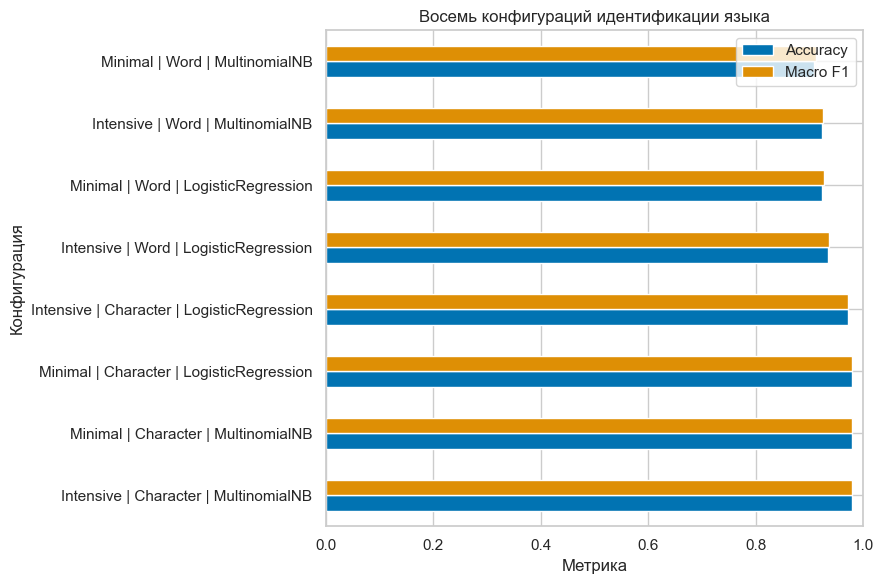

In [26]:
preprocessing_strategies = {"Intensive": preprocess_intensive, "Minimal": preprocess_minimal}
feature_strategies = {
    "Word": {"analyzer": "word", "ngram_range": (1, 1), "max_features": 30000},
    "Character": {"analyzer": "char", "ngram_range": (1, 3), "max_features": 50000},
}
classifiers = {
    "MultinomialNB": MultinomialNB(alpha=0.5),
    "LogisticRegression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
}
language_models = {}
language_predictions = {}
language_result_rows = []
for prep_name, prep_function in preprocessing_strategies.items():
    for feature_name, feature_kwargs in feature_strategies.items():
        for classifier_name, classifier in classifiers.items():
            configuration = f"{prep_name} | {feature_name} | {classifier_name}"
            model = Pipeline([
                ("tfidf", TfidfVectorizer(preprocessor=prep_function, lowercase=False,
                                          min_df=2, sublinear_tf=True, **feature_kwargs)),
                ("model", clone(classifier)),
            ])
            model.fit(train_t4.text, train_t4.language)
            prediction = model.predict(test_t4.text)
            language_models[configuration] = model
            language_predictions[configuration] = prediction
            language_result_rows.append({"Configuration": configuration,
                                         "Accuracy": accuracy_score(test_t4.language, prediction),
                                         "Macro F1": f1_score(test_t4.language, prediction, labels=language_labels,
                                                              average="macro", zero_division=0)})
language_results = pd.DataFrame(language_result_rows).sort_values("Macro F1", ascending=False).reset_index(drop=True)
display(language_results.style.format({"Accuracy": "{:.3f}", "Macro F1": "{:.3f}"}))
language_results.set_index("Configuration")[["Accuracy", "Macro F1"]].plot.barh(figsize=(9, 6), xlim=(0, 1))
plt.title("Восемь конфигураций идентификации языка"); plt.xlabel("Метрика"); plt.ylabel("Конфигурация"); plt.tight_layout(); plt.show()

### 6.4 Предварительно обученный fastText lid.176

In [27]:
model_dir = DATA_DIR / "models"
model_dir.mkdir(parents=True, exist_ok=True)
fasttext_path = model_dir / "lid.176.ftz"
if not fasttext_path.exists():
    urllib.request.urlretrieve(
        "https://dl.fbaipublicfiles.com/fasttext/supervised-models/lid.176.ftz", fasttext_path
    )
fasttext_lid = fasttext.load_model(str(fasttext_path))

def fasttext_predict(texts):
    labels, probabilities = fasttext_lid.predict([preprocess_minimal(text).replace("\n", " ") for text in texts])
    predictions = [label[0].replace("__label__", "") for label in labels]
    confidence = [float(probability[0]) for probability in probabilities]
    return np.array(predictions), np.array(confidence)

fasttext_pred_t4, fasttext_confidence_t4 = fasttext_predict(test_t4.text.tolist())
language_predictions["fastText lid.176"] = fasttext_pred_t4
fasttext_row = {
    "Configuration": "fastText lid.176",
    "Accuracy": accuracy_score(test_t4.language, fasttext_pred_t4),
    "Macro F1": f1_score(test_t4.language, fasttext_pred_t4, labels=language_labels,
                         average="macro", zero_division=0),
}
all_language_results = pd.concat([language_results, pd.DataFrame([fasttext_row])], ignore_index=True).sort_values("Macro F1", ascending=False)
display(all_language_results.style.format({"Accuracy": "{:.3f}", "Macro F1": "{:.3f}"}))

,Configuration,Accuracy,Macro F1
0,Intensive | Character | MultinomialNB,0.980,0.980
1,Minimal | Character | MultinomialNB,0.979,0.979
2,Minimal | Character | LogisticRegression,0.979,0.979
3,Intensive | Character | LogisticRegression,0.971,0.972
8,fastText lid.176,0.959,0.971
4,Intensive | Word | LogisticRegression,0.935,0.936
5,Minimal | Word | LogisticRegression,0.923,0.926
6,Intensive | Word | MultinomialNB,0.922,0.925
7,Minimal | Word | MultinomialNB,0.908,0.912


### 6.5 Матрица ошибок лучшей обученной конфигурации

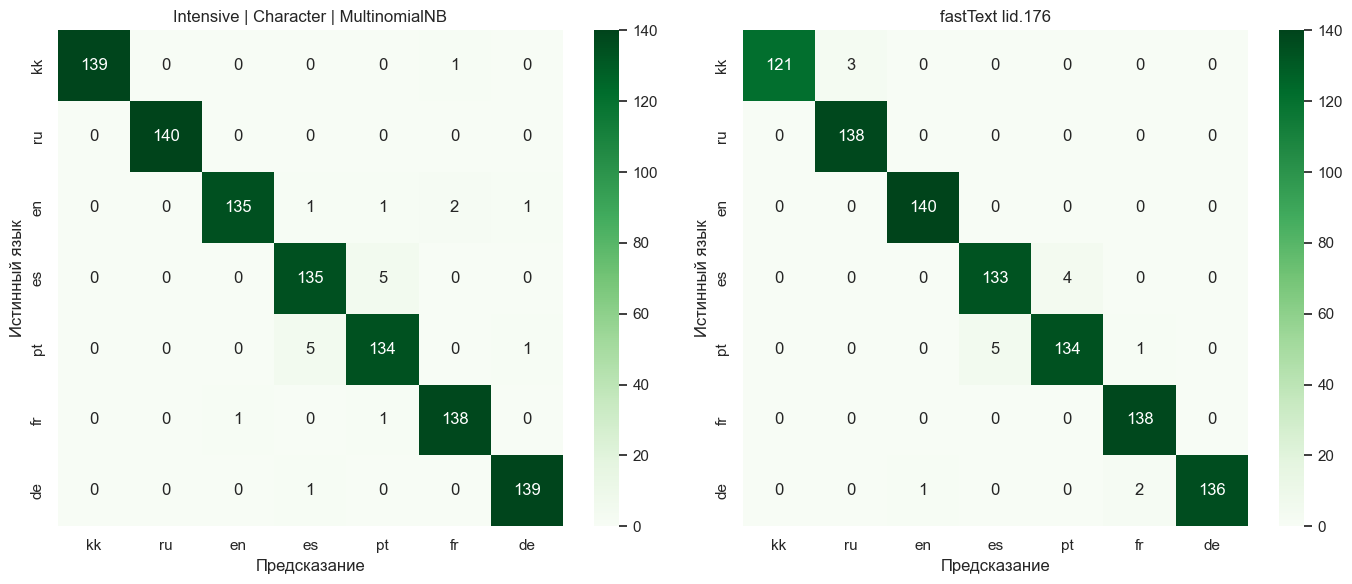

In [28]:
best_language_configuration = language_results.iloc[0].Configuration
best_language_model = language_models[best_language_configuration]
best_language_pred = language_predictions[best_language_configuration]
matrix_t4 = confusion_matrix(test_t4.language, best_language_pred, labels=language_labels)
fasttext_matrix_t4 = confusion_matrix(test_t4.language, fasttext_pred_t4, labels=language_labels)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for axis, matrix, title in [
    (axes[0], matrix_t4, best_language_configuration),
    (axes[1], fasttext_matrix_t4, "fastText lid.176"),
]:
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Greens", ax=axis,
                xticklabels=language_labels, yticklabels=language_labels)
    axis.set(title=title, xlabel="Предсказание", ylabel="Истинный язык")
plt.tight_layout(); plt.show()

### 6.6 Устойчивость A — длина текста

,Length,N,Accuracy,Macro F1
0,1–3,174,0.914,0.893
1,4–10,720,0.993,0.993
2,>10,86,1.000,1.000


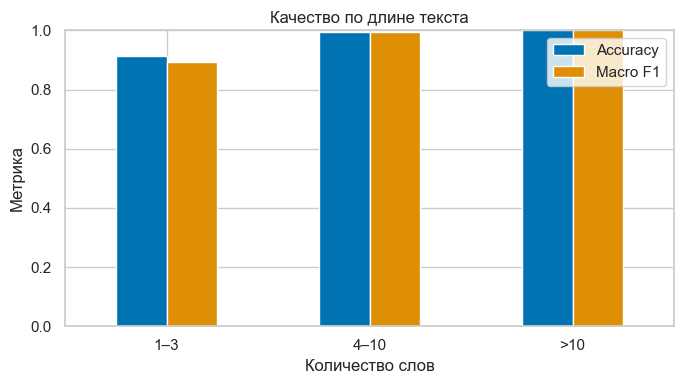

In [29]:
length_words = test_t4.text.str.split().str.len()
length_group = pd.cut(length_words, bins=[0, 3, 10, np.inf], labels=["1–3", "4–10", ">10"])
length_rows = []
for group in length_group.cat.categories:
    mask = length_group == group
    length_rows.append({"Length": group, "N": int(mask.sum()),
                        "Accuracy": accuracy_score(test_t4.language[mask], best_language_pred[mask]) if mask.any() else np.nan,
                        "Macro F1": f1_score(test_t4.language[mask], best_language_pred[mask], labels=language_labels,
                                             average="macro", zero_division=0) if mask.any() else np.nan})
length_results = pd.DataFrame(length_rows)
display(length_results.style.format({"Accuracy": "{:.3f}", "Macro F1": "{:.3f}"}))
length_results.set_index("Length")[["Accuracy", "Macro F1"]].plot.bar(figsize=(7, 4), ylim=(0, 1))
plt.title("Качество по длине текста"); plt.xlabel("Количество слов"); plt.ylabel("Метрика"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

### 6.7 Устойчивость B — контролируемые ошибки

,Condition,Accuracy,Macro F1
0,Original,0.980,0.980
1,With spelling error,0.982,0.982


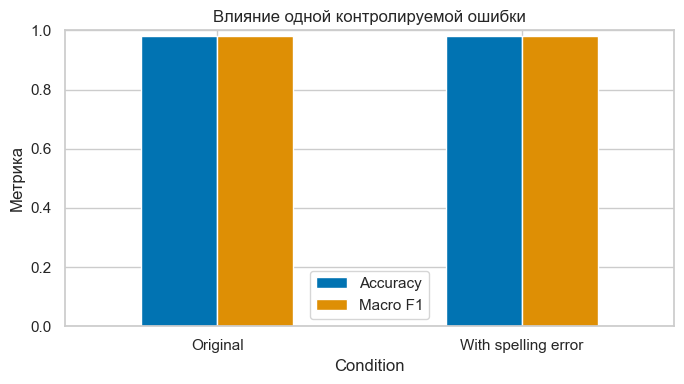

,original,noisy
3820,"Tu méprises Nick, n'est-ce pas ?","Tu mdprises Nick, n'est-ce pas ?"
3467,"O mundo deles é pequeno, mas o cuidam com o maior zelo.","O mundo deles é pequeеo, mas o cuidam com o maior zelo."
212,Менің кітаптарым жоқ.,Мені кітаптарым жоқ.
2549,¿Quién te has creído?,¿Quiln te has creído?
2697,Trabajo para una compañía petrolera.,Trabajo para une compañía petrolera.


In [30]:
NOISE_ALPHABET = "abcdefghijklmnopqrstuvwxyzабвгдежзийклмнопрстуфхцчшщыэюяәғқңөұүһі"

def add_controlled_noise(text, rng):
    characters = list(str(text))
    letter_positions = [index for index, character in enumerate(characters) if character.isalpha()]
    if not letter_positions:
        return text
    operation = rng.choice(["delete", "insert", "replace"])
    position = int(rng.choice(letter_positions))
    if operation == "delete" and len(letter_positions) > 1:
        del characters[position]
    elif operation == "insert":
        characters.insert(position, rng.choice(list(NOISE_ALPHABET)))
    else:
        characters[position] = rng.choice(list(NOISE_ALPHABET))
    return "".join(characters)

noise_rng = random.Random(RANDOM_STATE)
noisy_test_text = test_t4.text.map(lambda text: add_controlled_noise(text, noise_rng))
noisy_prediction = best_language_model.predict(noisy_test_text)
robustness_results = pd.DataFrame([
    {"Condition": "Original", "Accuracy": accuracy_score(test_t4.language, best_language_pred),
     "Macro F1": f1_score(test_t4.language, best_language_pred, labels=language_labels,
                          average="macro", zero_division=0)},
    {"Condition": "With spelling error", "Accuracy": accuracy_score(test_t4.language, noisy_prediction),
     "Macro F1": f1_score(test_t4.language, noisy_prediction, labels=language_labels,
                          average="macro", zero_division=0)},
])
display(robustness_results.style.format({"Accuracy": "{:.3f}", "Macro F1": "{:.3f}"}))
robustness_results.set_index("Condition").plot.bar(figsize=(7, 4), ylim=(0, 1))
plt.title("Влияние одной контролируемой ошибки"); plt.ylabel("Метрика"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
display(pd.DataFrame({"original": test_t4.text.head(5), "noisy": noisy_test_text.head(5)}))

### 6.8 Устойчивость C — казахско-русский code-switching

In [31]:
code_switching_sentences = [
    "Мен бүгін университетке бардым, но занятия отменили.",
    "Ертең жиналыс болады, пожалуйста, не опаздывай.",
    "Бұл кітап өте қызық, я прочитал её за вечер.",
    "Ауа райы жақсы, поэтому мы пошли гулять.",
    "Мен кофені ұнатамын, но сегодня заказал чай.",
    "Сабақ сағат тоғызда басталады, аудитория на втором этаже.",
    "Ол жаңа жұмыс тапты, и теперь очень доволен.",
    "Бүгін үйде қаламын, потому что немного устал.",
    "Досым Алматыға келді, мы встретились в центре.",
    "Маған осы ән ұнайды, особенно припев.",
    "Автобус кешігіп жатыр, придётся вызвать такси.",
    "Әжем бауырсақ пісірді, получилось очень вкусно.",
    "Мен тапсырманы аяқтадым, теперь можно отдыхать.",
    "Кешке кино көреміз, билеты уже куплены.",
    "Бұл мәселе маңызды, давайте обсудим завтра.",
    "Телефонымның қуаты аз, нужна зарядка.",
    "Ол қазақша жақсы сөйлейді, но пишет по-русски.",
    "Базардан жеміс сатып алдым, цены были высокие.",
    "Бүгін қар жауды, дороги стали скользкими.",
    "Жоба дайын болды, осталось сделать презентацию.",
    "Мен жаңа рецепт көрдім, попробую приготовить вечером.",
    "Поезд таңертең келеді, встретим гостей на вокзале.",
    "Оның пікірі дұрыс, я полностью согласен.",
    "Дәрігер демалуға кеңес берді, поэтому я взял выходной.",
    "Бала мектепке кетті, а родители остались дома.",
    "Кездесу онлайн өтеді, ссылку отправят позже.",
    "Менің ноутбугым баяу жұмыс істейді, нужен новый диск.",
    "Ағам көлік сатып алды, теперь ездит на работу сам.",
    "Біз тауға шықтық, вид оттуда был прекрасный.",
    "Емтихан қиын болды, но я ответил на все вопросы.",
]
code_switch_pred = best_language_model.predict(code_switching_sentences)
if hasattr(best_language_model.named_steps["model"], "predict_proba"):
    code_switch_conf = best_language_model.predict_proba(code_switching_sentences).max(axis=1)
else:
    decision = best_language_model.decision_function(code_switching_sentences)
    exp_scores = np.exp(decision - decision.max(axis=1, keepdims=True))
    code_switch_conf = (exp_scores / exp_scores.sum(axis=1, keepdims=True)).max(axis=1)
code_switch_results = pd.DataFrame({"Mixed sentence": code_switching_sentences,
                                   "Predicted language": code_switch_pred,
                                   "Confidence": code_switch_conf})
display(code_switch_results)
print("Accuracy не рассчитывается: у смешанного текста нет единственной истинной метки без заранее принятой политики разметки.")

,Mixed sentence,Predicted language,Confidence
0,"Мен бүгін университетке бардым, но занятия отменили.",ru,0.555199
1,"Ертең жиналыс болады, пожалуйста, не опаздывай.",kk,0.769248
2,"Бұл кітап өте қызық, я прочитал её за вечер.",kk,0.621960
3,"Ауа райы жақсы, поэтому мы пошли гулять.",ru,0.906492
4,"Мен кофені ұнатамын, но сегодня заказал чай.",ru,0.832325
5,"Сабақ сағат тоғызда басталады, аудитория на втором этаже.",kk,0.814306
6,"Ол жаңа жұмыс тапты, и теперь очень доволен.",ru,0.620247
7,"Бүгін үйде қаламын, потому что немного устал.",ru,0.539317
8,"Досым Алматыға келді, мы встретились в центре.",ru,0.606114
9,"Маған осы ән ұнайды, особенно припев.",kk,0.932876


Accuracy не рассчитывается: у смешанного текста нет единственной истинной метки без заранее принятой политики разметки.


### 6.9 Анализ ошибок и вывод

In [32]:
language_errors = test_t4[["text", "language"]].copy()
language_errors["prediction"] = best_language_pred
language_errors["words"] = language_errors.text.str.split().str.len()
language_errors = language_errors[language_errors.language != language_errors.prediction].head(5)
display(language_errors)

clean_f1 = robustness_results.loc[robustness_results.Condition == "Original", "Macro F1"].iloc[0]
noisy_f1 = robustness_results.loc[robustness_results.Condition == "With spelling error", "Macro F1"].iloc[0]
display(Markdown(
    f"**Вывод.** Лучшая обученная конфигурация — **{best_language_configuration}** "
    f"(Macro F1 = {language_results.iloc[0]['Macro F1']:.3f}). После внесения ошибок Macro F1 изменился "
    f"на {noisy_f1-clean_f1:+.3f}. Символьные n-граммы часто устойчивее на коротких строках, потому что "
    "используют части слов и характерные буквы даже при отсутствии полного словарного совпадения. Ошибки особенно "
    "вероятны на коротких интернациональных словах и между испанским/португальским; code-switching принудительно "
    "сводится моделью к одному классу, поэтому уверенность не означает одноязычность."
))

,text,language,prediction,words
2955,Fui mal-educado.,pt,es,2
3009,O ônibus chega tarde.,pt,es,4
2230,¿Tom sabe bailar?,es,pt,3
2936,Eu destruí a escola.,pt,es,4
1464,"Juice, please.",en,fr,2


**Вывод.** Лучшая обученная конфигурация — **Intensive | Character | MultinomialNB** (Macro F1 = 0.980). После внесения ошибок Macro F1 изменился на +0.002. Символьные n-граммы часто устойчивее на коротких строках, потому что используют части слов и характерные буквы даже при отсутствии полного словарного совпадения. Ошибки особенно вероятны на коротких интернациональных словах и между испанским/португальским; code-switching принудительно сводится моделью к одному классу, поэтому уверенность не означает одноязычность.

## 7. Общий вывод

In [33]:
display(Markdown(
    f"В четырёх экспериментах лучшие решения определялись только по измеренным метрикам. "
    f"Для тональности лучший Macro F1 показал **{results_t1.iloc[0].Model}** ({results_t1.iloc[0]['F1 Macro']:.3f}); "
    f"для жанров — **{genre_results.iloc[0].Model}** ({genre_results.iloc[0]['Macro F1']:.3f}); "
    f"для языка — **{all_language_results.iloc[0].Configuration}** ({all_language_results.iloc[0]['Macro F1']:.3f}). "
    f"В суммировании лучший ROUGE-L получил **{best_rouge_method}**. Результаты показывают, что более сложная "
    "модель не гарантирует преимущество: качество зависит от соответствия домену, представления признаков, длины "
    "и шума. Матрицы ошибок и реальные ошибочные примеры дополняют агрегированные метрики и показывают направления улучшения."
))

В четырёх экспериментах лучшие решения определялись только по измеренным метрикам. Для тональности лучший Macro F1 показал **Transformer** (0.761); для жанров — **Logistic Regression** (0.564); для языка — **Intensive | Character | MultinomialNB** (0.980). В суммировании лучший ROUGE-L получил **Abstractive**. Результаты показывают, что более сложная модель не гарантирует преимущество: качество зависит от соответствия домену, представления признаков, длины и шума. Матрицы ошибок и реальные ошибочные примеры дополняют агрегированные метрики и показывают направления улучшения.